In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import (
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    pipeline, DataCollatorForSeq2Seq, EarlyStoppingCallback
)
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from safetensors.torch import load_file

In [2]:
# Read the CSV file
data = pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/bible.csv")
extra_data=pd.read_csv("/kaggle/input/datasets/belovedorange/first-nagamese-english-parallel-corpus-fnpc-25/Nagamese Khobor Comic and Other Resouces.csv")

In [3]:
print("Bible dataset:", len(data))
print("Non-Bible dataset:", len(extra_data))

Bible dataset: 7950
Non-Bible dataset: 821


In [4]:
# Load model and tokenizer
model_name = "facebook/m2m100_418M"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

config.json:   0%|          | 0.00/908 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/298 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.94G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.94G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

In [5]:
data["source"] = "Bible"
extra_data["source"] = "Non-Bible"

df = pd.concat([data, extra_data], ignore_index=True)
df = df.dropna(subset=["English", "Nagamese"])
df = df.drop_duplicates(subset=["English", "Nagamese"])
# df = df.head(10)

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=61,
    stratify=df["source"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=61,
    stratify=temp_df["source"]
)

# Prepare text lists
train_source_texts = train_df["English"].tolist()
train_target_texts = train_df["Nagamese"].tolist()

val_source_texts = val_df["English"].tolist()
val_target_texts = val_df["Nagamese"].tolist()

test_source_texts = test_df["English"].tolist()
test_target_texts = test_df["Nagamese"].tolist()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 7014
Validation samples: 877
Testing samples: 877


In [6]:
import random
random.seed(7)
# Combine and shuffle the training data
combined_train = list(zip(train_source_texts, train_target_texts))
random.shuffle(combined_train)

# Unzip back into separate lists
train_source_texts, train_target_texts = zip(*combined_train)
train_source_texts = list(train_source_texts)
train_target_texts = list(train_target_texts)

In [7]:
from datasets import Dataset

# Tokenize function
def tokenize_function(examples):
    model_inputs = tokenizer(examples["source_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")
    labels = tokenizer(examples["target_texts"], return_tensors="pt",max_length=128, truncation=True, padding="max_length")["input_ids"]
    # labels = [[-100 if token == tokenizer.pad_token_id else token for token in label] for label in labels]
    model_inputs["labels"]=labels
    return model_inputs

# Convert lists to Hugging Face Dataset
train_dataset = Dataset.from_dict({"source_texts": train_source_texts, "target_texts": train_target_texts})
val_dataset = Dataset.from_dict({"source_texts": val_source_texts, "target_texts": val_target_texts})

# Tokenize datasets
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["source_texts", "target_texts"])



Map:   0%|          | 0/7014 [00:00<?, ? examples/s]

Map:   0%|          | 0/877 [00:00<?, ? examples/s]

In [8]:
print(train_dataset["input_ids"][0])
print(train_dataset["input_ids"][1])

print(train_dataset["labels"][0])
print(train_dataset["labels"][1])

[128022, 46277, 125612, 11956, 50, 316, 4, 2507, 10693, 103832, 316, 78, 1019, 118489, 203, 257, 4, 71586, 13635, 1949, 11956, 336, 13848, 667, 5, 46277, 125612, 11956, 50, 316, 4, 1197, 211, 42296, 13635, 71168, 10693, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[128022, 3952, 9988, 1307, 8778, 9348, 128, 96755, 128, 30557, 4, 36372, 1197, 123688, 128, 1197, 125045, 5, 46277, 1307, 13848, 8778, 9348, 128, 96755, 128, 1197, 125045, 4, 2507, 10693, 667, 128, 8251, 285, 8, 1027, 53, 1019, 8, 28184, 23909, 1586, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[

In [9]:
!pip install sacrebleu
import sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 6.4 MB/s eta 0:00:00


In [10]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)

    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)

    predictions = predictions.astype(np.int64)
    
    # ✅ Fix: clip to valid vocab range and replace negatives with pad token
    vocab_size = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size - 1)

    labels = np.where(
        labels == -100,
        tokenizer.pad_token_id,
        labels
    ).astype(np.int64)
    labels = np.clip(labels, 0, vocab_size - 1)  # ✅ also clip labels

    decoded_preds = tokenizer.batch_decode(predictions.tolist(), skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels.tolist(), skip_special_tokens=True)

    decoded_preds = [x.strip() for x in decoded_preds]
    decoded_labels = [x.strip() for x in decoded_labels]

    bleu = sacrebleu.corpus_bleu(decoded_preds, [decoded_labels])
    ter = sacrebleu.corpus_ter(decoded_preds, [decoded_labels])
    chrf = sacrebleu.corpus_chrf(decoded_preds, [decoded_labels])

    return {"bleu": bleu.score, "ter": ter.score, "chrf": chrf.score}

In [11]:
# Training Arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./results",
    logging_strategy="epoch", 
    eval_strategy="epoch", 
    save_strategy="epoch",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_ratio=0.1,
    seed = 40,
    save_total_limit=2,
    num_train_epochs=10,
    predict_with_generate=True,
    optim="adafactor", 
    report_to=[],
    fp16=True,
    logging_dir="./logs",
    # overwrite_output_dir=True,
    load_best_model_at_end=True,
    disable_tqdm=True
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=1)],
    compute_metrics=compute_metrics,
)

# Start Training
trainer.train()


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


{'loss': '2.872', 'grad_norm': '2.149', 'learning_rate': '4.971e-05', 'epoch': '1'}
{'eval_loss': '0.641', 'eval_bleu': '9.56', 'eval_ter': '111.3', 'eval_chrf': '36.86', 'eval_runtime': '2122', 'eval_samples_per_second': '0.413', 'eval_steps_per_second': '0.026', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.5828', 'grad_norm': '1.58', 'learning_rate': '4.448e-05', 'epoch': '2'}
{'eval_loss': '0.5123', 'eval_bleu': '20.2', 'eval_ter': '70.81', 'eval_chrf': '51.64', 'eval_runtime': '1956', 'eval_samples_per_second': '0.448', 'eval_steps_per_second': '0.028', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.2778', 'grad_norm': '3.678', 'learning_rate': '2.781e-05', 'epoch': '5'}
{'eval_loss': '0.4752', 'eval_bleu': '23.94', 'eval_ter': '62.12', 'eval_chrf': '53.88', 'eval_runtime': '1897', 'eval_samples_per_second': '0.462', 'eval_steps_per_second': '0.029', 'epoch': '5'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '1.24e+04', 'train_samples_per_second': '5.656', 'train_steps_per_second': '0.707', 'train_loss': '0.9048', 'epoch': '5'}


TrainOutput(global_step=4385, training_loss=0.9048379861098739, metrics={'train_runtime': 12400.3481, 'train_samples_per_second': 5.656, 'train_steps_per_second': 0.707, 'train_loss': 0.9048379861098739, 'epoch': 5.0})

In [12]:
model.save_pretrained("./m2m_model")
tokenizer.save_pretrained("./m2m_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./m2m_model/tokenizer_config.json',
 'm2m_model/vocab.json',
 'm2m_model/sentencepiece.bpe.model',
 './m2m_model/added_tokens.json')

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "./m2m_model",
    attn_implementation="eager"
).to(device)
model.eval()

Using device: cuda


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


M2M100ForConditionalGeneration(
  (model): M2M100Model(
    (shared): M2M100ScaledWordEmbedding(128112, 1024, padding_idx=1)
    (encoder): M2M100Encoder(
      (embed_tokens): M2M100ScaledWordEmbedding(128112, 1024, padding_idx=1)
      (embed_positions): M2M100SinusoidalPositionalEmbedding()
      (layers): ModuleList(
        (0-11): 12 x M2M100EncoderLayer(
          (self_attn): M2M100Attention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): ReLU()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
       

In [14]:
source_texts = val_source_texts
reference_texts = val_target_texts

In [15]:
# Translate source texts using the model
model.eval()
machine_translations = []
batch_size=32
for i in range(0, len(source_texts), batch_size):
    batch_texts = source_texts[i : i + batch_size]  # Slice batch
    inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    with torch.no_grad():
        outputs = model.generate(**inputs)
    
    batch_translations = tokenizer.batch_decode(outputs, skip_special_tokens=True)
    machine_translations.extend(batch_translations)

In [16]:
wrapped_reference_texts = [reference_texts] 
bleu = sacrebleu.corpus_bleu(machine_translations, wrapped_reference_texts)
print("BLEU Score:", bleu.score)
ter = sacrebleu.corpus_ter(machine_translations, wrapped_reference_texts)
print("TER Score:", ter.score)
chrf = sacrebleu.corpus_chrf(machine_translations, wrapped_reference_texts)
print("CHRF Score:", chrf.score)

BLEU Score: 22.756877351247862
TER Score: 64.12830681190704
CHRF Score: 53.34885193555324


In [17]:
n = 31
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: One person values one day above another. Another has concluded that every day is equal. Let each person be convinced in his own mind.
Translated: Ekta manu pora ek din to ekta pora bi bisi daam diye. Ekta manu pora tai laga bhabona to eke ase koikena jani loise.
Reference: Ekjon pora din ekta to dusra din pora bhal eneka bhabona kore, kintu kunba pora sob din to eke eneka bhabona kore. Sob manu pora nijor mon te he thik biswas koribo lage.


In [18]:
n = 81
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: Let both grow together until the harvest. At the time of the harvest I will say to the reapers, "First pull out the weeds and tie them in bundles to burn them, but gather the wheat into my barn."'"
Translated: Itu nimite, duijon bi eke logote kheti tak dangor thakibi. Kheti laga homoi te, moi kheti kora khan ke kobo, “Poila, itu ghas khan ulai dibi aru taikhan ke bondh kori kena juli thakibi, kintu gehu to Moi laga bacha te joma koribi.”’”
Reference: Itu nimite duijon ke bi eke logote dangor koribo dibi, kheti kata somoi naha tak. Jitia kheti kata somoi hobo titia moi kata manukhan ke kobo, “Poila biya ghas khan tani kena ulai lobi aru eke logote bandhi kena rakhibi julai dibo nimite, kintu gehu khan ke dhaan ghor te joma kori rakhibi.’”


In [19]:
n = 22
inputs = tokenizer(source_texts[n], return_tensors="pt", max_length=128, truncation=True).to(device)

# Generate output token IDs
with torch.no_grad():
    generated = model.generate(**inputs, max_length=128)
    translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)

print(f"Input: {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference: {reference_texts[n]}")

Input: What was sown on rocky ground is the person who hears the word and immediately receives it with joy,
Translated: Aru juntu pathor mati te rupai dise, itu he manu ase jun kotha hune aru joldi itu ke khushi pora grohon kore.
Reference: Juntu bijon pathor uporte phelai se, itu to eneka manu ase jun kotha huni loi aru loge-loge khushi pora grohon kore,


Input:      Because they poured out the blood of God's holy people and prophets, you have given them blood to drink; it is what they deserve."
Translated: Kilemane tai khan pobitro manu aru bhabobadi khan laga khun hali dise, aru Apni tai khan ke khun di kena khabole dise, aru tai khan itu khabole mon thakise.”
Reference:  Kilemane tai khan pobitro khan aru bhabobadi khan laga khun hali dise, Apni tai khan ke khun khabole nimite dise; Tai khan itu pabole nimite yogya ase.”


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

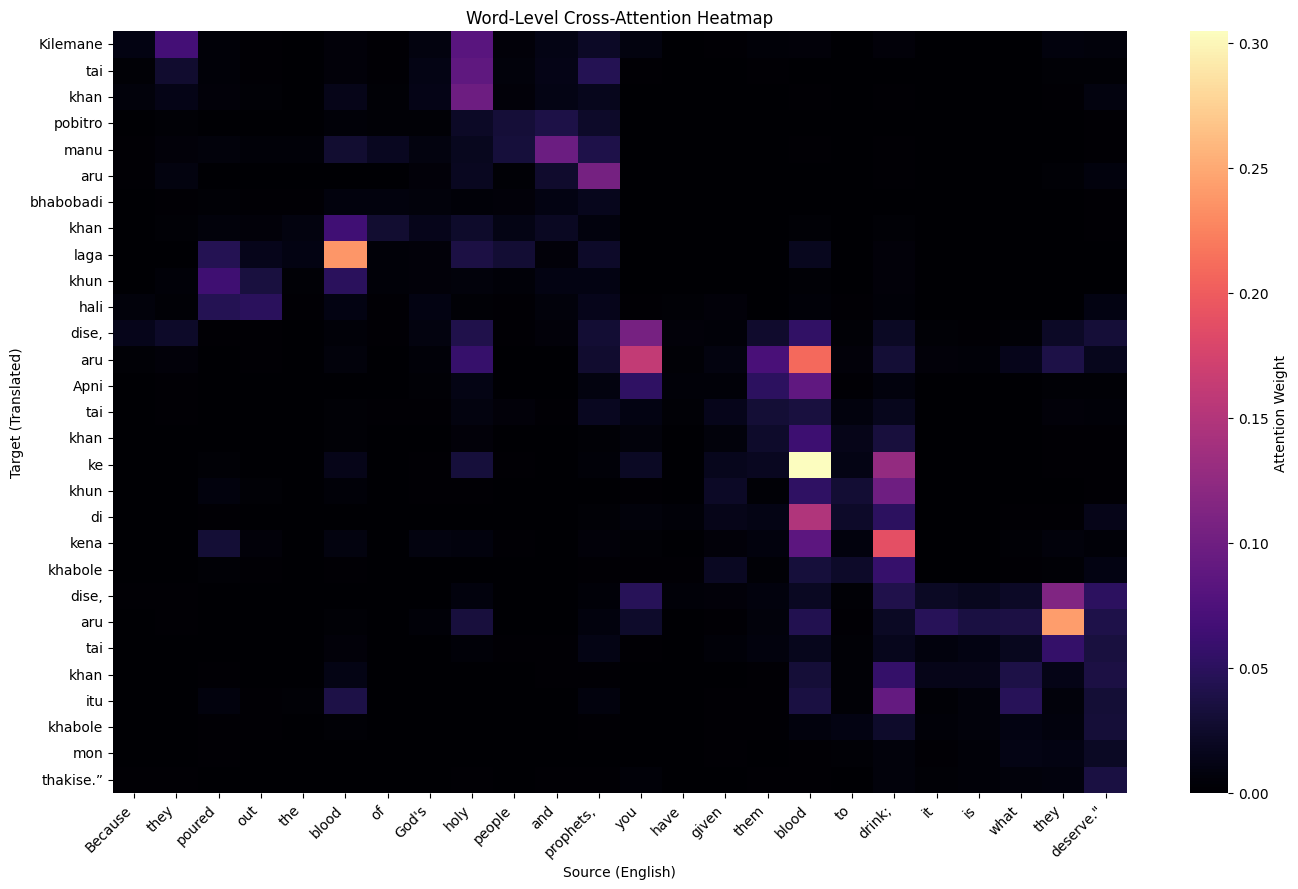


🔗 Word Alignments:

Target Word               →  Source Word
---------------------------------------------
Kilemane                  →  holy
tai                       →  holy
khan                      →  holy
pobitro                   →  and
manu                      →  and
aru                       →  prophets,
bhabobadi                 →  prophets,
khan                      →  blood
laga                      →  blood
khun                      →  poured
hali                      →  out
dise,                     →  you
aru                       →  blood
Apni                      →  blood
tai                       →  blood
khan                      →  blood
ke                        →  blood
khun                      →  drink;
di                        →  blood
kena                      →  drink;
khabole                   →  drink;
dise,                     →  they
aru                       →  they
tai                       →  they
khan                      →  drink;
itu               

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np

def merge_sentencepiece_tokens(tokens):
    words = []
    current_word = ""
    mapping = []
    word_idx = -1

    for i, tok in enumerate(tokens):
        if tok.startswith("▁") or tok.startswith("_"):  # SentencePiece or underscore-prefix
            if current_word:
                words.append(current_word)
            current_word = tok[1:]  # remove prefix
            word_idx += 1
        else:
            current_word += tok
        mapping.append(word_idx)
    if current_word:
        words.append(current_word)
    return words, mapping

def aggregate_attention(attn_matrix, src_map, tgt_map):
    num_tgt_words = max(tgt_map) + 1
    num_src_words = max(src_map) + 1
    agg_matrix = np.zeros((num_tgt_words, num_src_words))
    count_matrix = np.zeros((num_tgt_words, num_src_words))

    for i_tgt, tgt_word_idx in enumerate(tgt_map):
        for i_src, src_word_idx in enumerate(src_map):
            agg_matrix[tgt_word_idx][src_word_idx] += attn_matrix[i_tgt][i_src]
            count_matrix[tgt_word_idx][src_word_idx] += 1

    # Avoid division by zero
    count_matrix[count_matrix == 0] = 1
    return agg_matrix / count_matrix

# ----------------------------
# Your original pipeline
# ----------------------------
n = 28
tokenizer.src_lang = "en"
tokenizer.tgt_lang = "en"

inputs = tokenizer(
    source_texts[n], return_tensors="pt",
    max_length=128, truncation=True
).to(device)

with torch.no_grad():
    generated = model.generate(
        **inputs,
        max_length=128
    )

translated_text = tokenizer.decode(generated[0], skip_special_tokens=True)
print(f"Input:      {source_texts[n]}")
print(f"Translated: {translated_text}")
print(f"Reference:  {reference_texts[n]}")

decoder_input_ids = generated[:, :-1]

with torch.no_grad():
    out = model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"],
        decoder_input_ids=decoder_input_ids,
        output_attentions=True,
        return_dict=True
    )

cross_attn_avg = out.cross_attentions[-1][0].mean(dim=0)  # [tgt_len, src_len]

# ── Token filtering ───────────────────────────────────────────────
special_ids = set(tokenizer.all_special_ids)

src_token_ids = inputs["input_ids"][0].tolist()
tgt_token_ids = decoder_input_ids[0].tolist()

# Build index maps: only keep non-special tokens, track their positions
src_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(src_token_ids) if tid not in special_ids]
tgt_keep = [(i, tokenizer.convert_ids_to_tokens(tid)) 
            for i, tid in enumerate(tgt_token_ids) if tid not in special_ids]

src_indices, src_tokens_clean = zip(*src_keep) if src_keep else ([], [])
tgt_indices, tgt_tokens_clean = zip(*tgt_keep) if tgt_keep else ([], [])

src_indices = list(src_indices)
tgt_indices = list(tgt_indices)
src_tokens_clean = list(src_tokens_clean)
tgt_tokens_clean = list(tgt_tokens_clean)

# ── Slice attention to only non-special token positions ───────────
attn_np = cross_attn_avg.cpu().numpy()
attn_filtered = attn_np[np.ix_(tgt_indices, src_indices)]  # shape: [n_tgt_tokens, n_src_tokens]

# ── Merge subword tokens → words ──────────────────────────────────
src_words, src_map = merge_sentencepiece_tokens(src_tokens_clean)
tgt_words, tgt_map = merge_sentencepiece_tokens(tgt_tokens_clean)

word_attn = aggregate_attention(attn_filtered, src_map, tgt_map)

# ── Font fix for non-Latin scripts ────────────────────────────────
import matplotlib.font_manager as fm
# Use a font that supports Indic scripts if available, else fall back
try:
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSans/NotoSans-Regular.ttf",
        "/tmp/NotoSans-Regular.ttf"
    )
    prop = fm.FontProperties(fname="/tmp/NotoSans-Regular.ttf")
    font_name = prop.get_name()
    plt.rcParams["font.family"] = font_name
except Exception:
    pass  # silently skip if download fails

# ── Plot ──────────────────────────────────────────────────────────
plt.figure(figsize=(14, 9))
sns.heatmap(word_attn,
            xticklabels=src_words,
            yticklabels=tgt_words,
            cmap="magma",
            vmin=0, vmax=word_attn.max(),  # auto-scale vmax
            cbar_kws={"label": "Attention Weight"})
plt.title("Word-Level Cross-Attention Heatmap")
plt.xlabel("Source (English)")
plt.ylabel("Target (Translated)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ── Alignments ────────────────────────────────────────────────────
print("\n🔗 Word Alignments:\n")
print(f"{'Target Word':<25} →  Source Word")
print("-" * 45)
for tgt_idx, tgt_word in enumerate(tgt_words):
    if tgt_idx >= word_attn.shape[0]:
        break

    if word_attn.shape[1] == 0 or len(src_words) == 0:
        continue

    src_idx = int(np.argmax(word_attn[tgt_idx]))

    if src_idx < len(src_words):
        print(f"{tgt_word:<25} →  {src_words[src_idx]}")